nohup singularity exec  --nv /home/dillin01/cmr/cmrsim_jupyter.sif jupyter nbconvert --to notebook --execute ~/cmr/Untitled.ipynb --output=~/cmr/new.ipynb &

In [ ]:
import sys
# sys.path.append("../")
sys.path.insert(0, "./cmrsim")
sys.path.insert(0, "./cmrseq")
sys.path.insert(0, "./cmrsim/notebooks")

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ['CUDA_VISIBLE_DEVICES'] = "1"

import tensorflow as tf
gpu = tf.config.get_visible_devices("GPU")
print(gpu)
if gpu:
    tf.config.experimental.set_memory_growth(gpu[0], True)

: 

### Define sequence folder to load JSON sequence description from

In [ ]:
folder_name = 'cmrseq_venc50_bernstein_BW892'
rps = 500 / 60

In [ ]:
# 3rd Party dependencies 
from pint import Quantity
import pyvista
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from copy import deepcopy
from tqdm.notebook import tqdm
from time import perf_counter
from IPython.display import clear_output

# Project library cmrsim
import sys
import local_functions
import cmrsim
import cmrseq
import cmrsim.utils.particle_properties as part_factory

In [ ]:
from scipy.spatial.transform import Rotation


class ConstantRotationTrajectory(cmrsim.trajectory._base.BaseTrajectoryModule):
    """Implements an analytic trajectory of particles rotating about an arbitrary
    rotational axis in 3D with constant angular velocity.
    
    On instantiation, a 4x4 matrix :math:`T` is computed from the specified position and
    direction of the rotational axis, to transform the problem to a rotation
    about the z-axis in a new coordinate system.

    .. math::

        \\vec{r}\\prime = T^{-1}R_zT\\vec{r}

    
    :param angular_velocity:
    :param center_position: (3, ) 3D vector specifying the positional offset of 
            to rotational axis, in units of meter
    :param rotation_axis: (3, ) 3D vector specifying the direction of the rotational
            axis (this is normalized internally).
    """
    #: angular velocity in rotations per second (Hz)
    angular_velocity: float
    #: 3D position of the bottom end of the rotational axis
    center_position: tf.Tensor
    #: Rotational axis orientation
    rotation_axis: tf.Tensor
    #: (4, 4) Rotation matrix to transform the coordinate system in which 
    #: the rotation is performed about the z-axis
    _rot_mat: np.ndarray
    #: Inverse of the coordinate transform _rot_mat
    _rot_mat_inv: np.ndarray
    #: (4, 4) Translation in homogenous coordinates to account for positional
    #: offset of the rotation center
    _translate: np.ndarray
    #: inverse of _translate
    _translate_inv: np.ndarray
    
    def __init__(self, angular_velocity: Quantity,
                 center_position: Quantity,
                 rotation_axis: np.ndarray):
        # Save arguments:
        self.angular_velocity = angular_velocity.m_as("Hz")
        self.center_position = center_position.m_as("m")
        self.rotation_axis = rotation_axis / np.linalg.norm(rotation_axis)

        # As rotation about an arbitrary axes is treated as rotation about z-axis
        # where the coordinates are transformed beforehand, the corresponding 
        # transformation matrices need to be computed:
        # Rotation
        tmp, _ = Rotation.align_vectors(self.rotation_axis, np.array([0., 0., 1.]))
        self._rotmat = np.eye(4, 4)
        self._rotmat[:3, :3] = tmp.as_matrix()
        tmp_inv, _ = Rotation.align_vectors(np.array([0., 0., 1.]), self.rotation_axis)
        self._rotmat_inv = np.eye(4, 4)
        self._rotmat_inv[:3, :3] = tmp_inv.as_matrix()
        
        # Translation
        self._translate = np.eye(4, 4)
        self._translate[:3, 3] = -self.center_position
        self._translate_inv = np.eye(4, 4)
        self._translate_inv[:3, 3] = self.center_position
        
    def __call__(self, initial_positions: tf.Tensor, timing: tf.Tensor,
                 **kwargs) -> (tf.Tensor, dict):
        """
        :param initial_positions: (N, 3) tensor containing the initial
                    position of N particles
        :param timing: (t, ) 1D-tensor containing all time-points at which the
                    trajectory will be evaluated
        :return: (new positions (N, t, 3), additional fields)
        """
        delta_phi = 2 * np.pi * self.angular_velocity / 1000 * timing
        rotation_matrices = tf.stack([tf.stack([tf.math.cos(delta_phi), tf.math.sin(delta_phi), tf.zeros_like(delta_phi), tf.zeros_like(delta_phi)], axis=-1),
                                      tf.stack([-tf.math.sin(delta_phi), tf.math.cos(delta_phi), tf.zeros_like(delta_phi), tf.zeros_like(delta_phi)], axis=-1),
                                      tf.stack([tf.zeros_like(delta_phi), tf.zeros_like(delta_phi), tf.ones_like(delta_phi), tf.zeros_like(delta_phi)], axis=-1),
                                      tf.stack([tf.zeros_like(delta_phi), tf.zeros_like(delta_phi), tf.zeros_like(delta_phi), tf.ones_like(delta_phi)], axis=-1)],
                                     axis=-2)
        tmp = tf.concat([initial_positions, tf.ones_like(initial_positions[:, :1])], 1)
        tmp = tf.einsum("ij, nj -> ni", self._translate, tmp)
        tmp = tf.einsum("ij, tj -> ti", self._rotmat, tmp)
        tmp = tf.einsum("tij, nj -> nti", rotation_matrices, tmp)
        tmp = tf.einsum("ij, ntj -> nti", self._rotmat_inv, tmp)
        tmp = tf.einsum("ij, ntj -> nti", self._translate_inv, tmp)
        return tmp[..., :3], {}

    def increment_particles(self, particle_positions: tf.Tensor, dt: tf.Tensor, **kwargs):
        """
        :param particle_positions: (N, 3) tensor containing the initial
                    position of N particles
        :param dt: 0D-tensor containing the time-step for which the trajectory
                    will be evaluated
        :return: (new positions (N, 3), additional fields)
        """
        dt_expand = tf.reshape(dt, [1,])
        new_positions, _ = self(particle_positions, dt_expand)
        return new_positions[:, 0], {}

In [ ]:
import cmrseq

# Define MR-system specifications
system_specs = cmrseq.SystemSpec(max_grad=Quantity(50, "mT/m"), max_slew=Quantity(200., "mT/m/ms"),
                                 grad_raster_time=Quantity(0.01, "ms"),
                                 rf_raster_time=Quantity(0.01, "ms"),
                                 adc_raster_time=Quantity(0.01,"ms"))

# Define Fourier-Encoding parameters
fov = Quantity([200, 200], "mm")
matrix_size = (100, 50)
res = fov / matrix_size
print("Resolution:", res)
n_dummy = 25
center_index = np.array(matrix_size) // 2 + np.mod(matrix_size, 2)
print(center_index)

# Define imaging slice parameters
slice_thickness = Quantity(6, "mm")
slice_position = Quantity([0., 0., 0.], "m")
adc_duration=Quantity(4., "ms")
readout_direction = np.array([0., 0., 1.]) # readout along scanner Z, (FH)
slice_normal = np.array([0., 1., 0.])
slice_position_offset = Quantity(0.5, "cm")

# Define RF-exication parameters (coupled with seeding slice atm)
flip_angle=Quantity(np.pi/4, "rad")
pulse_duration = Quantity(1., "ms")
RF_slice_normal = np.array([0., 1., 0.]) # Slice along scanner Y, (AP)
RF_slice_position = Quantity([0., 0., 0.], "m")
FA = np.pi/4

# Define Reseeding slice parameters
seeding_slice_position = Quantity([0.03, 0.005, -0.025], "m")
seeding_slice_normal = np.array([0.3, 0., 1.])
seeding_slice_thickness = Quantity(35, "mm")
seeding_pixel_spacing = np.array((0.5e-3, 0.5e-3, 0.5e-3)) # resolution of seeding mesh, mm
seeding_slice_bb = Quantity([6, 6, 4], "cm")
seeding_particle_density = 10 # per 1/mm*3

# Define initial filling
initial_fill_normal = np.array([0., 1., 0.])
initial_fill_position = Quantity([0., 0.005, 0.], "m")
initial_fill_thickness = Quantity(50, "mm")
initial_fill_bounding_box = Quantity([25, 25, 25], "cm")
lookup_mesh_spacing = np.array((0.5e-3, 0.5e-3, 0.5e-3)) # resolution of lookup mesh, mm



Loading sequence from json:   0%|          | 0/908 [00:00<?, ?it/s]

Plotting sequence:   0%|          | 0/907 [00:00<?, ?it/s]

Plotting k-space:   0%|          | 0/883 [00:00<?, ?it/s]

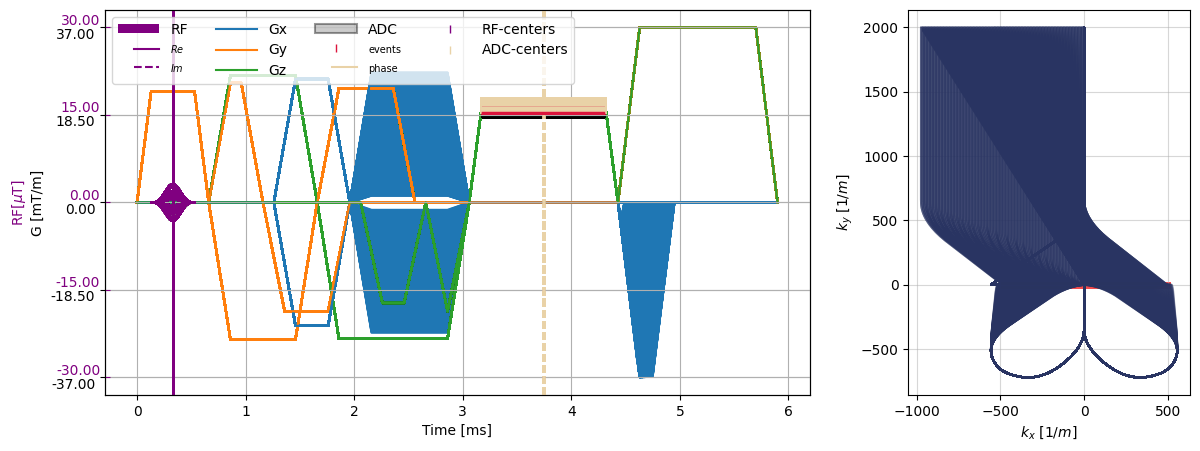

In [6]:
from cmrseq.io import sequence_from_json
from cmrseq.io import PulseSeqFile

from natsort import natsorted
from pathlib import Path
import cmrseq

from cmrseq.utils import get_rotation_matrix
# from cmrseq.utils import get_rotation_matrix

sequence_list = []

pathlist = list(Path(folder_name).glob('**/*.json'))
pathlist = natsorted(pathlist, key=str)

for path in tqdm(pathlist, desc='Loading sequence from json'):
    sequence_list.append(sequence_from_json(str(path)))

# rot_matrix = get_rotation_matrix(slice_normal=np.array([0, 1, 0]), readout_direction=np.array([1, 0, 0]))
# print(rot_matrix)

rot_matrix = cmrseq.OMatrix(Quantity(0., "m"),
                                 slice_normal=np.array([0., 1., 0.]),
                                 readout_direction=np.array([0., 0., 1.]),
                                 system_specs=system_specs)

for sequence in sequence_list:    
    sequence.register_omatrix(rot_matrix, rf_pulses=[(sequence.get_block(partial_string_match='rf_excitation_0')[0], sequence.get_block(partial_string_match='slice_select_0')[0])])
    sequence.register_omatrix(rot_matrix, gradients=sequence.get_block(partial_string_match='sSSGrad'))
    sequence.register_omatrix(rot_matrix, gradients=[('crusher_slice_0')])
    
    sequence.register_omatrix(rot_matrix, gradients=sequence.get_block(partial_string_match='sPEGrad'))
    sequence.register_omatrix(rot_matrix, gradients=sequence.get_block(partial_string_match='pe_rewinder'))
    
    sequence.register_omatrix(rot_matrix, gradients=sequence.get_block(partial_string_match='sROGrad'))
    sequence.register_omatrix(rot_matrix, gradients=sequence.get_block(partial_string_match='trapezoidal_readout_0'))
    sequence.register_omatrix(rot_matrix, gradients=sequence.get_block(partial_string_match='crusher'))

f, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [5, 2]})
cmrseq.plotting.plot_sequence(sequence_list[0], axes=a1, adc_yoffset=15.7)
# cmrseq.plotting.plot_sequence(sequence_list[-1], axes=a1, adc_yoffset=15.7)
for seq in tqdm(sequence_list[1:], desc='Plotting sequence'):
    cmrseq.plotting.plot_sequence(seq, axes=[f.axes[-1], a1, a1, a1], format_axes=False, adc_yoffset=15.7)
for s in tqdm(sequence_list[n_dummy:], desc='Plotting k-space'):
    cmrseq.plotting.plot_kspace_2d(s, ax=a2, k_axes=[0, 1])
    

plt.savefig(os.path.join(folder_name, f'{folder_name}_{rps}Hz_sequenceJSON.png'))

In [7]:
spacing = (0.0005, 0.0005, 0.0005)

dimensions = (200, 200, 5)

origin = tuple((-np.array(spacing) * np.array(dimensions) / 2).tolist())
print(spacing, dimensions, origin)

uniform_mesh = pyvista.ImageData(spacing=spacing, dimensions=dimensions, origin=origin)
inner_radius = 0.0
outer_radius = 0.0647

# initial_positions = np.array(uniform_mesh.points, dtype=np.float32)
initial_positions = np.array(uniform_mesh.points + np.random.standard_normal(uniform_mesh.points.shape) * np.max(spacing) / 2, dtype=np.float32)
# n_seeds = int(10)
# r = dimensions[0] * np.sqrt(np.random.uniform(0, 1, n_seeds))
# theta = np.random.uniform(0, 1, n_seeds)
# initial_positions = np.array([r*np.cos(theta), r*np.sin(theta)])

n_mesh = 150
extent = 0.1
x_mesh, y_mesh, z_mesh = np.meshgrid(np.linspace(-extent, extent, n_mesh), np.linspace(-extent, extent, n_mesh), np.linspace(-extent/50, extent/50, n_mesh))

initial_positions = np.float32(np.column_stack([x_mesh.ravel(), y_mesh.ravel(), z_mesh.ravel()]))


# print(np.max(initial_positions[:]))

initial_positions = np.float32(initial_positions + 1e-6*np.random.standard_normal(initial_positions.shape))
# initial_positions = np.float32(initial_positions)

print(initial_positions.shape)

initial_positions = initial_positions[np.where(np.logical_and(np.linalg.norm(initial_positions[:, :2], axis=1) > inner_radius,
                                                              np.linalg.norm(initial_positions[:, :2], axis=1) < outer_radius))]
n_parts = initial_positions.shape[0]


initial_positions_temp = deepcopy(initial_positions)
# initial_positions[:, 0] = initial_positions_temp[:, 2]
initial_positions[:, 1] = initial_positions_temp[:, 2]
initial_positions[:, 2] = initial_positions_temp[:, 1]
np.random.shuffle(initial_positions)

print(n_parts)

coco = cmrsim.bloch.submodules.ConcomitantFields(gamma=system_specs.gamma.m_as("MHz/T"), b0=system_specs.b0*2, device="GPU:0")

properties = {"M0":  np.ones(n_parts, np.float32),
              "T1":  np.ones(n_parts, np.float32) * 400,
              "T2":  np.ones(n_parts, np.float32) * 300,
              "magnetization": part_factory.norm_magnetization()(n_parts),
              "initial_position": initial_positions,
            #   "off_res": np.ones(n_parts, np.float32).reshape(-1, 1) * initial_positions[:, 1].reshape(-1, 1)*0.1
              }

(0.0005, 0.0005, 0.0005) (200, 200, 5) (-0.05, -0.05, -0.00125)
(3375000, 3)
1096800


In [8]:
trajectory_module = ConstantRotationTrajectory(angular_velocity=Quantity(rps, "Hz"),
                                               center_position=Quantity([0., 0., 0.], "m"),
                                               rotation_axis=np.array([0., 1., 0.]))

In [9]:
timing = np.linspace(0, 100, 50).astype(np.float32)
r_traj = trajectory_module(initial_positions=initial_positions.astype(np.float32), timing=timing)[0].numpy()
r_traj.shape

import pyvista
pyvista.close_all()
pyvista.start_xvfb()
plotter = pyvista.Plotter(off_screen=True)

local_functions.add_custom_axes(plotter)
local_functions.animate_trajectories(plotter, r_traj.transpose(1, 0, 2)[:, ::1000],
                                     timing, "test.gif",
                                     text_kwargs=dict(color="black"),
                                     visualize_trajectories=True,
                                     visualize_trajectories_max_length=4,
                                     mesh_kwargs=dict(color="gray"),
                                     )
plotter.close()

Rendering Mesh-Animation from 0.000ms to 100.000 ms:   0%|          | 0/50 [00:00<?, ?it/s]

In [10]:
for idx_dummy, seq in enumerate(sequence_list):
    if len(seq.partial_sequence(partial_string_match=('adc_0'), copy_blocks=False).blocks) > 0:
        break

print(f'Found {idx_dummy} dummy shots in sequence list.')


# Define off-resonsance submodule
# offres = cmrsim.bloch.submodules.OffResonance(gamma=system_specs.gamma.m_as("MHz/T"), device="GPU:0")


time_rf_dummy, rf_grid_dummy, grad_grid_dummy, adc_on_grid_dummy = [np.stack(v) for v in cmrseq.utils.grid_sequence_list(sequence_list[:idx_dummy], force_uniform_grid=False)]
print([v.shape for v in [time_rf_dummy, rf_grid_dummy, grad_grid_dummy, adc_on_grid_dummy]])

print("Input shapes for dummy Bloch Module:\n  ", "\n   ".join([f"{time_rf_dummy.shape=}", f"{rf_grid_dummy.shape=}",
                                                          f"{grad_grid_dummy.shape=}", f"{adc_on_grid_dummy.shape=}"]))

time_rf, rf_grid, grad_grid, adc_on_grid = [np.stack(v) for v in cmrseq.utils.grid_sequence_list(sequence_list[idx_dummy:], force_uniform_grid=False)]
print([v.shape for v in [time_rf, rf_grid, grad_grid, adc_on_grid]])


print("Input shapes for Bloch Module:\n  ", "\n   ".join([f"{time_rf.shape=}", f"{rf_grid.shape=}",
                                                          f"{grad_grid.shape=}", f"{adc_on_grid.shape=}"]))

module = cmrsim.bloch.GeneralBlochOperator(name="rf", gamma=system_specs.gamma_rad.m_as("rad/mT/ms"),
                                           time_grid=time_rf[0], gradient_waveforms=grad_grid,
                                           rf_waveforms=rf_grid, adc_events=adc_on_grid, device="GPU:0",
                                           submodules=[coco])

spoiling_mod = cmrsim.bloch.PerfectSpoiling("spoiling_op")

n_samples = tf.shape(module.time_signal_acc[0])[0]
n_repetitions = tf.shape(module.gradient_waveforms)[0]

Found 12 dummy shots in sequence list.
[(12, 591), (12, 5902), (12, 591, 3), (12,)]
Input shapes for dummy Bloch Module:
   time_rf_dummy.shape=(12, 591)
   rf_grid_dummy.shape=(12, 5902)
   grad_grid_dummy.shape=(12, 591, 3)
   adc_on_grid_dummy.shape=(12,)
[(896, 1600), (896, 1600), (896, 1600, 3), (896, 1600, 2)]
Input shapes for Bloch Module:
   time_rf.shape=(896, 1600)
   rf_grid.shape=(896, 1600)
   grad_grid.shape=(896, 1600, 3)
   adc_on_grid.shape=(896, 1600, 2)


In [11]:
r = properties.pop("initial_position")
m = properties.pop("magnetization")

for rbatch, mbatch, dict_batch in tqdm(tf.data.Dataset.from_tensor_slices((r, m, properties)).batch(int(1.5e5)), desc="Phantom Batches", leave=False):
    _ = module(trajectory_module=trajectory_module, initial_position=rbatch, magnetization=mbatch, run_parallel=True, **dict_batch)

Phantom Batches:   0%|          | 0/8 [00:00<?, ?it/s]

I0000 00:00:1745785688.645002   55302 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


In [21]:
print(tf.stack(module.time_signal_acc, axis=0).numpy().shape)

# 4d flow
time_signal = tf.stack(module.time_signal_acc, axis=0).numpy().reshape((224, 4, 224))

time_signal = tf.transpose(time_signal, perm=[1, 0, 2])

# np.save(os.path.join(folder_name, f'{rps}Hz_ftime_signal.npy'), time_signal.numpy())

image = tf.signal.fftshift(tf.signal.ifft2d(tf.signal.ifftshift(time_signal, axes=(1, 2))), axes=(1, 2)).numpy()

# image_mag = np.abs(image[0, :, :])
# image_mag = np.abs(np.mean(image, axis=0))
image_mag = np.mean(np.abs(image), axis=0)

image = image[1, :, :] / image[0, :, :]
print(image.shape)

(896, 224)
(224, 224)


In [22]:
# taken from https://gist.github.com/jakevdp/91077b0cae40f8f8244a
def discrete_cmap(N, base_cmap=None):
    """Create an N-bin discrete colormap from the specified input map"""

    # Note that if base_cmap is a string or None, you can simply do
    #    return plt.cm.get_cmap(base_cmap, N)
    # The following works for string, None, or a colormap instance:

    base = plt.get_cmap(base_cmap)
    color_list = base(np.linspace(0, 1, N))
    cmap_name = base.name + str(N)
    # return base.from_list(cmap_name, color_list, N)
    return plt.cm.colors.ListedColormap(color_list, color_list, N)

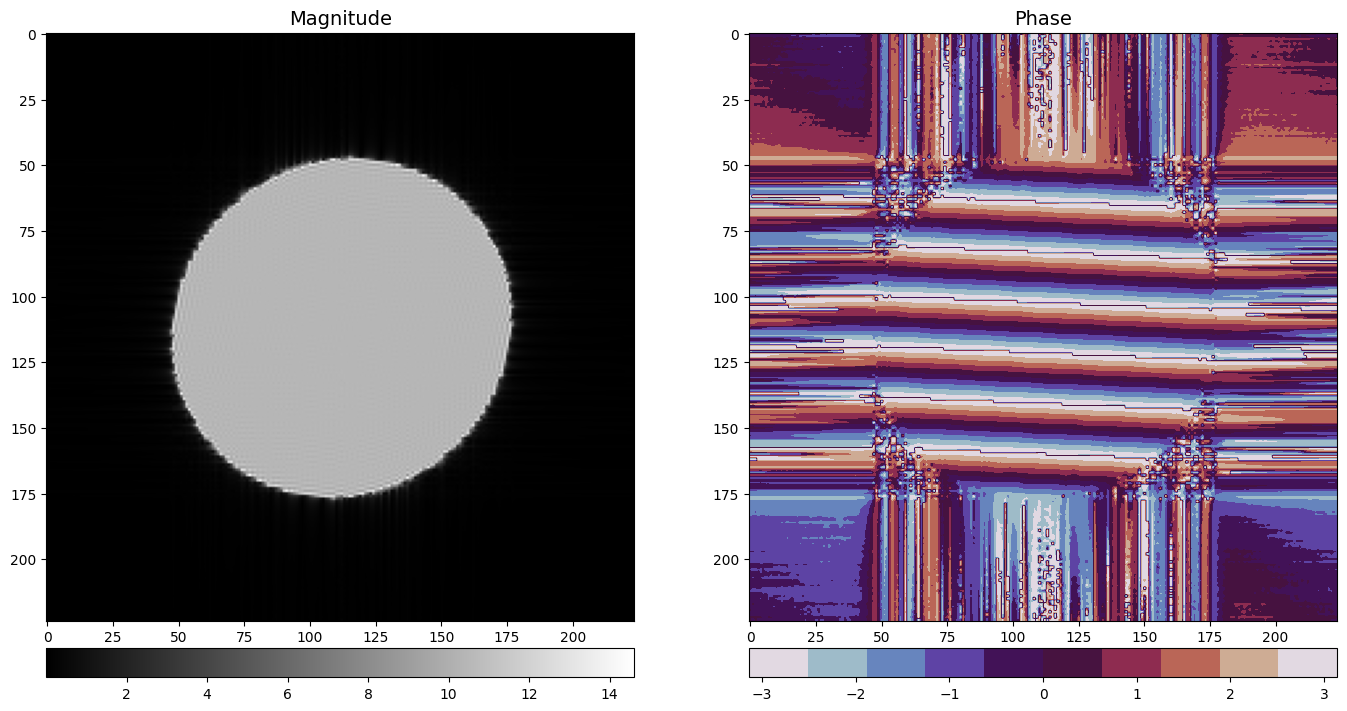

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

abs_plot = axes[0].imshow((np.abs(np.squeeze(image_mag))), cmap="gray")
fig.colorbar(abs_plot, ax=axes[0], fraction=0.05, pad=0.005,    orientation="horizontal")

phase_plot = axes[1].imshow(np.angle(np.squeeze(image)), cmap=discrete_cmap(10, "twilight"), vmin=-np.pi, vmax=np.pi)

# masked
# phase_plot = axes[1].imshow(np.angle(np.squeeze(image))* (image_mag / np.max(image_mag[:])), cmap="twilight", vmin=-np.pi/2, vmax=np.pi/2)

# phase_plot = axes[1].imshow(np.angle(np.squeeze(image))* (image_mag / np.max(image_mag[:])), cmap="twilight", vmin=-np.pi, vmax=np.pi)
fig.colorbar(phase_plot, ax=axes[1], fraction=0.05, pad=0.005, orientation="horizontal")
# [(_.set_yticks([]), _.set_xticks([])) for _ in axes]
[_.set_title(t, fontsize=14) for _, t in zip(axes, ["Magnitude", "Phase"])]

plt.savefig(os.path.join(folder_name, f'{folder_name}_{rps}Hz_result.png'))